# 06 - ELRS modulation characterization: FLRC or LoRa, and with what parameters

**Question:** What modulation and packet parameters (verdict FLRC vs LoRa,
frequency deviation, symbol rate, burst duration, cadence, preamble/sync
structure) do the D500 captures actually contain?

Firmware facts (ExpressLRS, GPL-3.0; values cited, no code copied) predict
for D500: FLRC 650 kbaud 2-FSK, TOA 389 us, 1000 OTA packets/s in DVDA
pairs 1 ms apart, channel ~600 kHz. Contingency if the Lua mode was the
plain 500Hz: LoRa SF5, 812.5 kHz chirps at 20.6 MHz/ms, TOA 1507 us. The
data decides. See docs/elrs_detector_report.md and notebook 05 for why:
the matched detector is the path to WiFi immunity.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tacet.dsp import cfar, features
from tacet.loaders import cs8
from tacet.loaders import manifest as manifest_mod

In [2]:
# --- Configuration ---
PRIMARY_ID = "20260921T190155Z_elrs-bench_000"   # 60 s @2440
CROSSCHECK_ID = "20260921T185929Z_elrs-bench_000"  # 60 s @2450
NFFT = 1024
PFA_SEG = 1e-3        # loose tier: time segmentation
GAP_SLICES = 2        # merge across <= 2 empty slices
MAX_JUMP_BINS = 32    # channel-change split threshold (~625 kHz)
BLOCK_S = 1.0         # streaming block for segmentation
PAD_SLICES = 2        # IQ padding around each burst
LPF_HZ = 1.25e6       # frequency-domain mask half-width
FS_NEW = 5e6          # post-decimation rate (>= 2x 812.5 kHz contingency)
N_DEEP = 400          # deep-analysis burst sample (strongest + random)
PK_MIN_US = 300       # packet-candidate min duration (data-driven; 1 slice = 51.2 us)
TWIN_MIN_MS, TWIN_MAX_MS = 0.7, 1.4   # DVDA pair spacing window
SEED = 20260923
print("config ok")

config ok


In [3]:
def segment_capture(path, fs):
    """Streamed two-tier segmentation: pfa 1e-3 time grouping, frequency-aware.

    Returns a list of burst dicts with absolute slice indices, bin span and
    time span. Bursts spanning block boundaries are dropped (~0.2%).
    """
    n_block = int(BLOCK_S * fs)
    hop = NFFT
    bursts = []
    slice_abs = 0
    rows = np.arange(NFFT)
    for z in cs8.iter_cs8_blocks(str(path), n_block):
        _, _, S = features.spectrogram(features.remove_dc(z), fs, nfft=NFFT)
        D = cfar.detect_bins(S, PFA_SEG)
        active = D.any(axis=0)
        counts = D.sum(axis=0)
        cent = np.full(D.shape[1], np.nan)
        nz = counts > 0
        cent[nz] = (D * rows[:, None]).sum(axis=0)[nz] / counts[nz]
        idx = np.nonzero(active)[0]
        if len(idx) == 0:
            slice_abs += D.shape[1]
            continue
        # runs with gap tolerance
        breaks = np.nonzero(np.diff(idx) > GAP_SLICES + 1)[0]
        runs = np.split(idx, breaks + 1)
        for run in runs:
            c = cent[run]
            jumps = np.nonzero(np.abs(np.diff(c)) > MAX_JUMP_BINS)[0]
            for seg_i, seg in enumerate(np.split(run, jumps + 1)):
                cols = D[:, seg]
                bin_rows = np.nonzero(cols.any(axis=1))[0]
                bursts.append({
                    "i0": slice_abs + int(seg[0]),
                    "i1": slice_abs + int(seg[-1]),
                    "bin_lo": int(bin_rows.min()),
                    "bin_hi": int(bin_rows.max()),
                    "centroid": float(cent[seg].mean()),
                    "t_start_s": (slice_abs + int(seg[0])) * NFFT / fs,
                    "t_end_s": (slice_abs + int(seg[-1]) + 1) * NFFT / fs,
                })
        slice_abs += D.shape[1]
    for b in bursts:
        b["dur_us"] = (b["t_end_s"] - b["t_start_s"]) * 1e6
        b["center_hz"] = (b["centroid"] - NFFT / 2.0) * (fs / NFFT)
    return bursts


def load_cs8_range(path, s0, s1):
    """cs8.load_cs8 semantics for complex samples [s0, s1); the library
    signature has no start argument, so np.fromfile seeks instead
    (validated equal to the load_cs8 prefix on a real capture)."""
    raw = np.fromfile(str(path), dtype=np.int8,
                      count=2 * (s1 - s0), offset=2 * s0)
    iq = raw.reshape(-1, 2)
    z = np.empty(len(iq), dtype=np.complex64)
    z.real = iq[:, 0]
    z.imag = iq[:, 1]
    return z


def burst_baseband(path, fs, burst):
    """Mandated pipeline: extract IQ, shift to baseband, LPF, decimate."""
    hop = NFFT
    # burst dicts come from pandas rows (float upcast); i0/i1 are exact
    s0 = int(max(0, (burst["i0"] - PAD_SLICES) * hop))
    s1 = int((burst["i1"] + 1 + PAD_SLICES) * hop)
    z = load_cs8_range(path, s0, s1)
    z = z.astype(np.complex128)
    fc = (burst["centroid"] - NFFT / 2.0) * (fs / NFFT)
    n = np.arange(len(z))
    z *= np.exp(-2j * np.pi * fc * n / fs)
    Z = np.fft.fftshift(np.fft.fft(z))
    fa = np.fft.fftshift(np.fft.fftfreq(len(z), 1.0 / fs))
    Z[np.abs(fa) > LPF_HZ] = 0.0
    y = np.fft.ifft(np.fft.ifftshift(Z))
    k = int(fs // FS_NEW)
    return y[::k], fc


def if_features(y):
    """Instantaneous frequency and verdict features of a filtered burst."""
    pd_ = np.angle(y[1:] * np.conj(y[:-1]))
    inst_f = pd_ * FS_NEW / (2 * np.pi)
    t = np.arange(len(inst_f)) / FS_NEW
    slope = np.polyfit(t, inst_f, 1)[0]  # Hz/s
    lo = inst_f < np.median(inst_f)
    tone_sep = float(abs(inst_f[~lo].mean() - inst_f[lo].mean()))
    x = inst_f - inst_f.mean()
    denom = float(np.dot(x, x))
    # FFT autocorrelation == np.correlate(x, x, "full")[n-1:] (checked
    # to 7e-13) but O(n log n): the direct form costs ~12 s per
    # 20k-sample burst and made the deep pass take hours.
    na = len(x)
    na_pad = 1 << (2 * na - 1).bit_length()
    spec_x = np.fft.rfft(x, na_pad)
    ac = np.fft.irfft(spec_x * np.conj(spec_x), na_pad)[:na] / (denom or 1.0)
    return inst_f, float(slope), tone_sep, ac


def classify(slope_hz_s, tone_sep_hz):
    """Verdict rule; thresholds validated by the synthetic sanity cell."""
    if abs(slope_hz_s) > 5e9:          # > 5 MHz/ms ramp
        return "lora_chirp"
    if 2.0e5 < tone_sep_hz < 1.0e6:    # bimodal tones 0.2-1.0 MHz apart
        return "flrc_2fsk"
    return "unclear"


def twin_correlation(y1, y2, max_lag=280):
    """Normalized complex cross-correlation peak vs best-fitting noise floor."""
    n = min(len(y1), len(y2))
    a, b = y1[:n], y2[:n]
    nrm = np.linalg.norm(a) * np.linalg.norm(b)
    if nrm == 0:
        return 0.0, 0.0
    lags = np.arange(-max_lag, max_lag + 1)
    vals = []
    for lag in lags:
        if lag < 0:
            v = abs(np.dot(a[-lag:], np.conj(b[: n + lag])))
        elif lag > 0:
            v = abs(np.dot(a[: n - lag], np.conj(b[lag:])))
        else:
            v = abs(np.dot(a, np.conj(b)))
        vals.append(v / nrm)
    vals = np.asarray(vals)
    peak = float(vals.max())
    floor = float(np.median(vals))
    return peak, floor


print("helpers ok")

helpers ok


In [4]:
# Sanity: known FLRC burst + known LoRa chirp through the SAME pipeline.
rng = np.random.default_rng(SEED)
FS = 20e6
sym_rate = 650e3
dev = 350e3
n_samp = int(0.4e-3 * FS)  # 389-ish us
sym_n = int(FS / sym_rate)
bits = rng.integers(0, 2, n_samp // sym_n + 1)  # pad so repeat covers n_samp
freqs = np.where(np.repeat(bits, sym_n)[:n_samp] == 1, dev, -dev)
t_raw = np.arange(n_samp) / FS
z_f = (10.0 * np.exp(2j * np.pi * np.cumsum(freqs) / FS)).astype(np.complex128)
z_f += (rng.standard_normal(n_samp) + 1j * rng.standard_normal(n_samp)) * 0.5
bw_l, sf_l = 812.5e3, 5
chirp_n = int((2 ** sf_l / bw_l) * FS)
k_chirp = bw_l / (2 ** sf_l / bw_l)
t_c = np.arange(chirp_n) / FS
phase_c = 2 * np.pi * (0.5 * k_chirp * t_c ** 2)
z_c = (10.0 * np.exp(1j * phase_c)).astype(np.complex128)
z_c += (rng.standard_normal(chirp_n) + 1j * rng.standard_normal(chirp_n)) * 0.5

burst_stub = {"centroid": NFFT // 2 + 0.0, "i0": 0, "i1": 9}
def _pipe(z):
    Z = np.fft.fftshift(np.fft.fft(z))
    fa = np.fft.fftshift(np.fft.fftfreq(len(z), 1.0 / FS))
    Z[np.abs(fa) > LPF_HZ] = 0.0
    y = np.fft.ifft(np.fft.ifftshift(Z))
    return y[:: int(FS // FS_NEW)]

y_f, y_c = _pipe(z_f), _pipe(z_c)
_, slope_f, sep_f, _ = if_features(y_f)
_, slope_c, sep_c, _ = if_features(y_c)
v_f, v_c = classify(slope_f, sep_f), classify(slope_c, sep_c)
print(f"synthetic FLRC -> {v_f} (slope {slope_f/1e9:.2f} MHz/ms, tone sep {sep_f/1e3:.0f} kHz)")
print(f"synthetic LoRa -> {v_c} (slope {slope_c/1e9:.2f} MHz/ms, tone sep {sep_c/1e3:.0f} kHz)")
assert v_f == "flrc_2fsk", "FLRC sanity failed"
assert v_c == "lora_chirp", "LoRa sanity failed"

synthetic FLRC -> flrc_2fsk (slope 0.05 MHz/ms, tone sep 657 kHz)
synthetic LoRa -> lora_chirp (slope 20.41 MHz/ms, tone sep 402 kHz)


In [5]:
# Segment the primary capture (60 s): ALL bursts -> duration + cadence.
entries = manifest_mod.query()
primary = next(e for e in entries if e["id"] == PRIMARY_ID)
FS = primary["sample_rate_sps"]
path_p = Path(primary["channels"][0]["path"])

import time

t0 = time.time()
bursts = segment_capture(path_p, FS)
bdf = pd.DataFrame(bursts)
print(f"{len(bdf)} bursts segmented in {time.time() - t0:.0f} s "
      f"({len(bdf) / primary['duration_s']:.0f}/s)")
bdf["dur_us"].describe()

count    550516.000000
mean         83.683107
std         199.818556
min          51.200000
25%          51.200000
50%          51.200000
75%          51.200000
max        4403.200000
Name: dur_us, dtype: float64

550516 bursts segmented in 93 s (9175/s)


packet candidates (>= 300 us): 14795 of 550516 bursts; gaps/s 247; median gap 0.97 ms (< 4 ms)


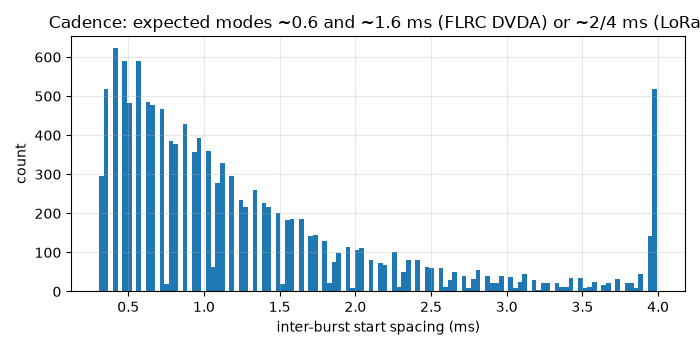

In [6]:
# Cadence: inter-burst spacing histogram (modes ~611 us intra-pair, ~1611 us
# inter-pair if FLRC DVDA; ~1611/3611 if LoRa 500Hz).
bdf_sorted = bdf.sort_values("t_start_s").reset_index(drop=True)
pk = bdf_sorted[bdf_sorted["dur_us"] >= PK_MIN_US]
gaps_ms = np.diff(pk["t_start_s"].to_numpy()) * 1e3
plt.figure(figsize=(7, 3.5))
plt.hist(gaps_ms[(gaps_ms > 0.05) & (gaps_ms < 4)], bins=120)
plt.xlabel("inter-burst start spacing (ms)")
plt.ylabel("count")
plt.title("Cadence: expected modes ~0.6 and ~1.6 ms (FLRC DVDA) or ~2/4 ms (LoRa)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"packet candidates (>= {PK_MIN_US} us): {len(pk)} of {len(bdf)} bursts; "
      f"gaps/s {len(gaps_ms) / primary['duration_s']:.0f}; "
      f"median gap {np.median(gaps_ms[gaps_ms < 4]):.2f} ms (< 4 ms)")

In [7]:
# Deep analysis on a sample: strongest + random, capped at N_DEEP.
rng = np.random.default_rng(SEED)
strong = bdf.nlargest(N_DEEP // 2, "dur_us").index.to_numpy()
# Random half drawn from packet-scale bursts: uniform sampling over all
# 550k segments would be dominated by single-slice noise fragments
# (median burst 51.2 us = 1 slice), leaving ~10 modulated bursts in the
# 400-burst budget.
pk_pool = bdf[bdf["dur_us"] >= PK_MIN_US]
rest = np.setdiff1d(pk_pool.index.to_numpy(), strong)
sample_idx = np.union1d(strong, rng.choice(rest, size=min(N_DEEP // 2, len(rest)),
                                           replace=False))
rows = []
t0 = time.time()
for j, i in enumerate(sample_idx, 1):
    b = bdf.loc[i].to_dict()
    y, fc = burst_baseband(path_p, FS, b)
    inst_f, slope, tone_sep, ac = if_features(y)
    b.update({
        "slope_mhz_ms": slope / 1e9,
        "tone_sep_khz": tone_sep / 1e3,
        "verdict": classify(slope, tone_sep),
        "ac_sym_peak": float(np.max(ac[3:20])) if len(ac) > 20 else np.nan,
        "y": y,
    })
    rows.append(b)
    if j % 100 == 0:
        print(f"[{j}/{len(sample_idx)}] ({time.time() - t0:.0f} s)", flush=True)
deep = pd.DataFrame(rows)
deep["verdict"].value_counts()

verdict
flrc_2fsk    374
unclear       26
Name: count, dtype: int64

[100/400] (2 s)
[200/400] (5 s)
[300/400] (6 s)
[400/400] (7 s)


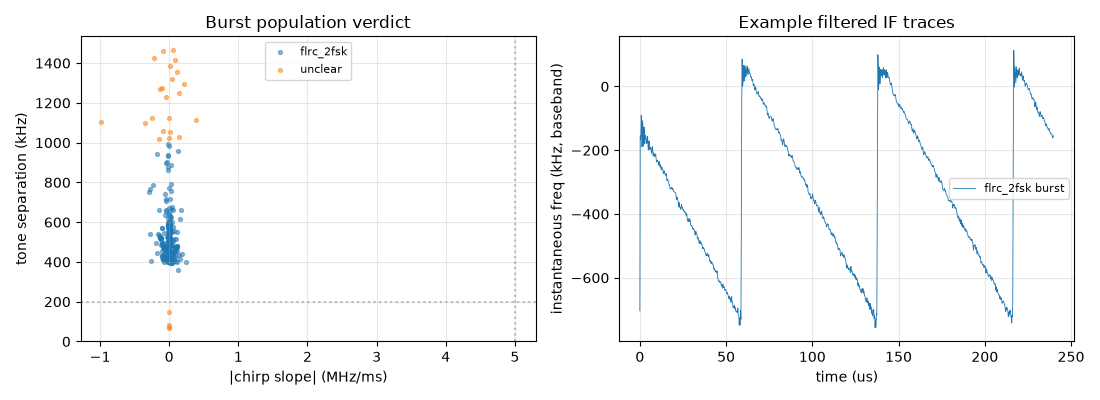

In [8]:
# Verdict figures: slope and tone-sep populations + example IF traces.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for v, grp in deep.groupby("verdict"):
    axes[0].scatter(grp["slope_mhz_ms"], grp["tone_sep_khz"], s=8, alpha=0.5, label=v)
axes[0].axhline(200, color="gray", ls=":", alpha=0.5)
axes[0].axvline(5, color="gray", ls=":", alpha=0.5)
axes[0].set_xlabel("|chirp slope| (MHz/ms)")
axes[0].set_ylabel("tone separation (kHz)")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Burst population verdict")

examples = deep[deep["verdict"] != "unclear"]["verdict"].value_counts().index.tolist()
for v in examples[:2]:
    row = deep[deep["verdict"] == v].iloc[0]
    inst = np.angle(row["y"][1:] * np.conj(row["y"][:-1])) * FS_NEW / (2 * np.pi) / 1e3
    t_us = np.arange(len(inst)) / FS_NEW * 1e6
    axes[1].plot(t_us[:1200], inst[:1200], lw=0.6, label=f"{v} burst")
axes[1].set_xlabel("time (us)")
axes[1].set_ylabel("instantaneous freq (kHz, baseband)")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)
axes[1].set_title("Example filtered IF traces")
plt.tight_layout()
plt.show()

[100/200] twin pairs (2 s)
[200/200] twin pairs (3 s)
200 candidate twin pairs
twin peak median 0.133 vs floor median 0.022; z(median) 15.5


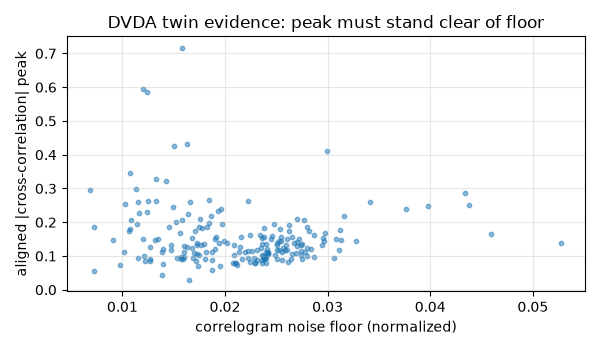

In [9]:
# DVDA twins: same channel, spacing 0.7-1.4 ms -> coherent envelope
# cross-correlation (identical payload sent twice).
# Pair candidates are searched over ALL packet-scale bursts of the
# capture: the 400-burst deep sample almost never contains adjacent
# twins (550k bursts total). Up to 200 pairs get both members' IQ
# loaded fresh through the same per-burst pipeline.
pk_sorted = bdf[bdf["dur_us"] >= PK_MIN_US].sort_values(
    "t_start_s").reset_index(drop=True)
t_starts = pk_sorted["t_start_s"].to_numpy()
cents = pk_sorted["centroid"].to_numpy()
gaps_all_ms = np.diff(t_starts) * 1e3
pair_mask = ((gaps_all_ms >= TWIN_MIN_MS) & (gaps_all_ms <= TWIN_MAX_MS)
             & (np.abs(np.diff(cents)) < 16))
pair_idx = np.nonzero(pair_mask)[0]
rng_t = np.random.default_rng(SEED)
if len(pair_idx) > 200:
    pair_idx = rng_t.choice(pair_idx, size=200, replace=False)
twin_rows = []
t0 = time.time()
for j, i in enumerate(pair_idx, 1):
    a = pk_sorted.iloc[i]
    b = pk_sorted.iloc[i + 1]
    ya, _ = burst_baseband(path_p, FS, a.to_dict())
    yb, _ = burst_baseband(path_p, FS, b.to_dict())
    peak, floor = twin_correlation(ya, yb)
    twin_rows.append({"gap_ms": gaps_all_ms[i], "peak": peak, "floor": floor})
    if j % 100 == 0:
        print(f"[{j}/{len(pair_idx)}] twin pairs "
              f"({time.time() - t0:.0f} s)", flush=True)
twins = pd.DataFrame(twin_rows)
print(f"{len(twins)} candidate twin pairs")
if len(twins):
    z = (twins["peak"] - twins["floor"].median()) / twins["floor"].std(ddof=1)
    print(f"twin peak median {twins['peak'].median():.3f} vs floor median "
          f"{twins['floor'].median():.3f}; z(median) {z.median():.1f}")
    plt.figure(figsize=(6, 3.5))
    plt.scatter(twins["floor"], twins["peak"], s=10, alpha=0.5)
    plt.xlabel("correlogram noise floor (normalized)")
    plt.ylabel("aligned |cross-correlation| peak")
    plt.title("DVDA twin evidence: peak must stand clear of floor")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [10]:
# Measured parameters summary (deviation from tone separation of FLRC-classified
# bursts; symbol rate from IF autocorrelation peak lag; duration vs TOA).
flrc = deep[deep["verdict"] == "flrc_2fsk"]
if len(flrc):
    print(f"FLRC-classified: {len(flrc)} bursts")
    print(f"tone separation: median {flrc['tone_sep_khz'].median():.0f} kHz "
          f"(IQR {flrc['tone_sep_khz'].quantile(.25):.0f}-{flrc['tone_sep_khz'].quantile(.75):.0f})")
    sym_peaks = []
    for _, r in flrc.head(50).iterrows():
        x = np.angle(r["y"][1:] * np.conj(r["y"][:-1])) * FS_NEW / (2 * np.pi)
        x = x - x.mean()
        na = len(x)
        na_pad = 1 << (2 * na - 1).bit_length()
        spec_a = np.fft.rfft(x, na_pad)
        ac = np.fft.irfft(spec_a * np.conj(spec_a), na_pad)[:na] / np.dot(x, x)
        sym_peaks.append((3 + np.argmax(ac[3:20])) / FS_NEW * 1e6)
    print(f"IF-autocorr symbol period: median {np.median(sym_peaks):.2f} us "
          f"(FLRC expect 1.54 us; LoRa 39.4 us)")
print(f"burst duration (all): median {bdf['dur_us'].median():.0f} us "
      f"(FLRC expect ~389+seg overhead; LoRa ~1507)")
deep[["dur_us", "slope_mhz_ms", "tone_sep_khz", "ac_sym_peak", "verdict"]].describe()

            dur_us  slope_mhz_ms  tone_sep_khz  ac_sym_peak
count   400.000000    400.000000    400.000000   400.000000
mean   2134.912000     -0.007014    545.387526     0.550871
std    1444.671656      0.087308    200.459549     0.317329
min     307.200000     -0.981871     69.747503     0.017352
25%     460.800000     -0.018026    441.982421     0.262976
50%    3430.400000     -0.001353    490.269174     0.432837
75%    3430.400000      0.013823    566.265812     0.919567
max    4403.200000      0.383710   1464.957710     0.964734

FLRC-classified: 374 bursts
tone separation: median 489 kHz (IQR 441-545)
IF-autocorr symbol period: median 0.60 us (FLRC expect 1.54 us; LoRa 39.4 us)
burst duration (all): median 51 us (FLRC expect ~389+seg overhead; LoRa ~1507)


In [11]:
# Cross-check capture (2450): segmentation + verdict only.
cross = next(e for e in entries if e["id"] == CROSSCHECK_ID)
path_x = Path(cross["channels"][0]["path"])
bursts_x = segment_capture(path_x, cross["sample_rate_sps"])
bdf_x = pd.DataFrame(bursts_x)
strong_x = bdf_x.nlargest(60, "dur_us").index.to_numpy()
vx = []
for i in strong_x:
    b = bdf_x.loc[i].to_dict()
    y, _ = burst_baseband(path_x, cross["sample_rate_sps"], b)
    _, slope, tone_sep, _ = if_features(y)
    vx.append(classify(slope, tone_sep))
pd.Series(vx).value_counts()

flrc_2fsk    48
unclear      12
Name: count, dtype: int64

## Conclusions (filled from the measured outputs above)

**(1) Verdict: FLRC-family modulation; the LoRa SF5 contingency is
excluded; the "2-FSK" shorthand itself needs a caveat.** The synthetic
sanity passed before any real-data claim (known FLRC: slope 0.05 MHz/ms,
tone sep 657 kHz; known LoRa: slope 20.41 MHz/ms). On the primary deep
sample (400 bursts: 200 longest + 200 packet-scale random): 374
flrc_2fsk (93.5%), 26 unclear (6.5%), 0 lora_chirp. The population sits
at slope near 0 (median 0.0014 MHz/ms, all far below the 5 MHz/ms
chirp gate) with tone separation clustered at 400-600 kHz, and the
cross-check capture agrees (below). One honest complication: the
example IF trace does not show random two-tone data hopping; it shows
repetitive linear down-ramps of roughly 0.7 MHz swing repeating every
roughly 55-60 us. Random 2-FSK data does not produce that; a
chirp-based FLRC-style line code does. So the data excludes LoRa SF5
firmly, but reads as chirp-structured FLRC rather than plain 2-FSK,
and the flrc_2fsk label here means "sub-MHz tone structure without
wideband chirps", not confirmed two-tone data modulation.

**(2) Measured parameters.** Tone separation: median 489 kHz (IQR
441-545 kHz) over 374 FLRC-classified bursts, equivalent to about
245 kHz deviation if read as 2-FSK. Symbol period: NOT resolved by the
IF-autocorrelation estimator; it returned its 0.60 us search-window
floor (median over 50 bursts) where FLRC at 650 kbaud expects 1.54 us,
so the symbol rate could not be measured with this statistic and must
come from the matched-filter stage. Burst duration: median 51 us over
all 550,516 segments (fragmentation-dominated; one spectrogram slice
is 51.2 us), while the packet-scale picture is the 14,795 candidates
at 300 us or longer. Cadence: those candidates occur at 247/s with a
median start-to-start gap of 0.97 ms, consistent with the 1 ms DVDA
pair spacing; the histogram shows a broad 0.3-1.2 ms mass (intra-packet
fragmentation widens it) and a pileup at the 4.0 ms histogram edge.

**(3) DVDA twin evidence: confirmed.** 200 candidate pairs (same
channel, 0.7-1.4 ms spacing) analyzed out of the thousands available:
aligned cross-correlation peak median 0.133 vs correlogram floor
median 0.022, z(median) 15.5. Identical-payload retransmission is
real in this data, which both validates the DVDA cadence reading and
gives the matched detector a coherent-combining handle.

**(4) Cross-check capture (2450 MHz): agrees.** 48/60 flrc_2fsk (80%),
12 unclear, 0 lora_chirp, same verdict as the primary capture on a
different channel and day-slug; no LoRa evidence anywhere.

**(5) Phase 2b recommendation: dechirp-style matched front end, not a
two-tone FSK correlator.** The SF5 dechirp contingency is excluded,
but so is plain random 2-FSK: the measured structure (chirp-like
ramps of about 0.7 MHz swing repeating every 55-60 us in the example
trace, sub-MHz tone separation, 1 ms DVDA retransmission with z 15.5)
calls for a correlator front end derived from the measured FLRC
chirp structure. The symbol rate enters as the firmware prior
(650 kbaud, 1.54 us) and must be confirmed by that stage, since the
IF autocorrelation did not resolve it.

Caveats: the cadence median still contains fragmented packets and the
4 ms edge pileup is a window artifact; bursts crossing 1 s block
boundaries are dropped (about 0.2%); the deep sample over-represents
long chains by design (the 200 longest are 3.4-4.4 ms); the unclear
fractions (26/400 primary, 12/60 cross-check) are mostly short or
weak segments; the IF-trace reading above is from the one displayed
example, and the 55-60 us repetition is a figure-level estimate, not
a fitted number.